<h1 style="font-family:verdana;"> <center> </center> </h1>
<h1 style="font-family:verdana;"> <center style="color:#159364; font-family:cursive; font-size:20px;">Informed Searches </center></h1>
<p><center style="color:#159364; font-family:cursive; font-size:20px;"> AL-2002 Artifical Intelligence Spring 2026</center></p>

***




# 🔖Informed Searches
<div class="alert alert-block alert-info" style="font-size:20px; font-family:verdana;">
    
</div>

# 🔬Overview
<div style="background-color:#fff1cc; padding: 20px;">
<p style="font-size:20px; font-family:verdana; line-height: 1.7em">While uninformed search algorithms explore the search space without additional knowledge.

While the **informed search** algorithms use heuristic information to guide the search process more effectively.
`Informed_Search = Search + Heuristic`

## ♟️**Heuristic Function**
In simple terms a heuristic function is a smart guess about how close we are to the goal,making them more efficient by focusing on the most promising paths.

*`h(n)`* `= Estimated cost from node n to the goal`
### Key Characteristics:

* **Admissibility:** A heuristic is admissible if it **never overestimates** the actual cost to reach the goal. This ensures the algorithm `finds the optimal solution`.
* **Consistency (or Monotonicity):** A heuristic is consistent if it **satisfies the triangle inequality**, meaning the estimated cost between two states is less than or equal to the actual cost.

**Note:** Heuristic functions are the backbone of informed search strategies, enabling faster and more effective.


#### **A * Algorithm**
* **Mechanics and Evaluation Function:**
  * A* calculates the total cost of a path using the formula:

  `f(n) = g(n) + h(n)`
  
   where:

  `g(n)`: Actual cost to reach node nnn.

  `h(n)`: Estimated cost (heuristic) to reach the goal from nnn.
* **Admissibility and Optimality:**
  * A* guarantees the shortest path if the heuristic is admissible (does not overestimate) and consistent (satisfies the triangle inequality).
#### **Greedy Best-First Search**
* **Mechanics and Evaluation Function:**
  * Focuses solely on the heuristic value `h(n)`, selecting nodes that seem closest to the goal.

**Comparison with A * :** While faster, it does not guarantee an optimal solution because it ignores the actual cost g(n).



<center><img src='https://media1.giphy.com/media/v1.Y2lkPTc5MGI3NjExdnFobG50Ynl5MzIzZXk1aWlrNWY2c2c4eXZ2cjJ6bGk1YWhvejBpeiZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/SWoSkN6DxTszqIKEqv/giphy.gif' height=480px width=700px></center>


# 📝 Types
* A* Search
* Greedy Best-First Search




# **A * Algorithm**
The A* algorithm is a widely used pathfinding algorithm in AI, designed to find the `most efficient route between two points`. It improves on earlier algorithms like Dijkstra’s Algorithm by incorporating a heuristic that **estimates the cost of reaching the goal from any given node**, making it more efficient in terms of computational time.

A* prioritizes nodes that are likely to lead to the goal by balancing two factors:

`g(n)`: The actual cost of reaching node n from the start.

`h(n)`: The heuristic estimate of the cost to reach the goal from node n.
***

###Pseudocode

1.  Initialize the open list.
2.  Initialize the closed list
    * put the starting node on the open list (you can leave its f at zero)
3.  while the open list is not empty

    a) find the node with the least f on the open list, call it `"q"`.

    b) pop q off the open list.
  
    c) generate q's successors and set their parents to q
   
    d) for each successor

        i) if successor is the goal, stop search
        
        ii) else, compute both g and h for successor
          successor.g = q.g + distance between
                              successor and q
          successor.h = distance from goal to
          successor (This can be done using many
          ways, we will discuss three heuristics-
          Manhattan, Diagonal and Euclidean
          Heuristics)
          
          successor.f = successor.g + successor.h
        iii) if a node with the same position as
            successor is in the OPEN list which has a
           lower f than successor, skip this successor
        iV) if a node with the same position as
            successor  is in the CLOSED list which has
            a lower f than successor, skip this successor
            otherwise, add  the node to the open list
     end (for loop)
  
    e) push q on the closed list
    end (while loop).


In [ ]:
import heapq

# Node class to store coordinates and costs
class Node:
    def __init__(self, x, y, g=0, h=0, parent=None):
        self.x = x
        self.y = y
        self.g = g  # Cost from start to node. (Position in grid)
        self.h = h  # Heuristic cost from node to goal. (start node to this node)
        self.f = g + h  # Total cost
        self.parent = parent

    def __lt__(self, other):
        return self.f < other.f #Compare which node is smaller

# Heuristic function (Manhattan Distance)
def heuristic(current_x, current_y, goal_x, goal_y):
    return abs(current_x - goal_x) + abs(current_y - goal_y)

# A* search algorithm
def a_star(grid, start, goal):
    open_list = []
    closed_list = set()

    # Pass individual coordinates to heuristic
    heapq.heappush(open_list, Node(start[0], start[1], 0, heuristic(start[0], start[1], goal[0], goal[1])))

    while open_list:
        current = heapq.heappop(open_list)

        if (current.x, current.y) == goal:
            path = []
            while current:
                path.append((current.x, current.y))
                current = current.parent
            return path[::-1]  # Return reversed path

        closed_list.add((current.x, current.y))

        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            neighbor_x, neighbor_y = current.x + dx, current.y + dy

            if (neighbor_x, neighbor_y) in closed_list or not is_walkable(grid, neighbor_x, neighbor_y):
                continue

            g = current.g + 1
            # Pass individual coordinates to heuristic
            h = heuristic(neighbor_x, neighbor_y, goal[0], goal[1])
            neighbor = Node(neighbor_x, neighbor_y, g, h, current)
            heapq.heappush(open_list, neighbor)

    return None  # No path found

# Helper function to check if a node is walkable
def is_walkable(grid, x, y):
    return 0 <= x < len(grid) and 0 <= y < len(grid[0]) and grid[x][y] == 0

# Example grid: 0 = walkable, 1 = obstacle
grid = [
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 1, 0, 0, 0],
    [0, 0, 0, 1, 0],
    [1, 0, 0, 0, 0]
]

start = (0, 0)
goal = (4, 4)

path = a_star(grid, start, goal)

print("Path:", path)

Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4)]


In [ ]:
from heapq import heappop, heappush

def a_star_search(graph: dict, start: str, goal: str, heuristic_values: dict):
    # A min heap is used to implement the priority queue for the open list.
    # Entries in the heap are tuples of the form (cost, node), ensuring that the entry with the lowest cost is always smaller during comparisons.

    open_list  = [(heuristic_values[start], start)]
    closed_list = set()
    while open_list:
        cost, node = heappop(open_list)

        # The algorithm ends when the goal node has been explored, NOT when it is added to the open list.
        if node == goal:
            return cost

        if node in closed_list:
            continue

        closed_list.add(node)

        # Subtract the heuristic value as it was overcounted.
        cost -= heuristic_values[node]

        for neighbor, edge_cost in graph[node]:
            if neighbor in closed_list:
                continue

            # f(x) = g(x) + h(x), where g(x) is the path cost and h(x) is the heuristic.
            neighbor_cost = cost + edge_cost + heuristic_values[neighbor]
            heappush(open_list, (neighbor_cost, neighbor))

    return -1  # No path found

EXAMPLE_GRAPH = {
    'S': [('A', 4), ('B', 10), ('C', 11)],
    'A': [('B', 8), ('D', 5)],
    'B': [('D', 15)],
    'C': [('D', 8), ('E', 20), ('F', 2)],
    'D': [('F', 1), ('I', 20), ('H', 16)],
    'E': [('G', 19)],
    'F': [('G', 13)],
    'H': [('J', 2), ('I', 1)],
    'I': [('K', 13), ('G', 5), ('J', 5)],
    'J': [('K', 7)],
    'K': [('G', 16)]
}

# Node heuristic values (admissible heuristic values for the nodes)
EXAMPLE_HEURISTIC_VALUES = {
    'S': 7,
    'A': 8,
    'B': 6,
    'C': 5,
    'D': 5,
    'E': 3,
    'F': 3,
    'G': 0,
    'H': 7,
    'I': 4,
    'J': 5,
    'K': 3
}

EXAMPLE_RESULT = a_star_search(EXAMPLE_GRAPH, 'S', 'G', EXAMPLE_HEURISTIC_VALUES)
print(EXAMPLE_RESULT)


23


# **Greedy Best-First Search**

In [ ]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt
class Node:
    def __init__(self, name, heuristic):
        self.name = name
        self.heuristic = heuristic

    def __lt__(self, other):
        return self.heuristic < other.heuristic
def greedy_best_first_search_hierarchical(graph, start, goal, heuristic, region_map):
    priority_queue = []
    heapq.heappush(priority_queue, Node(start, heuristic[start]))

    visited = set()
    path = {start: None}

    while priority_queue:
        current_node = heapq.heappop(priority_queue).name

        if current_node == goal:
            return reconstruct_path(path, start, goal)

        visited.add(current_node)

        current_region = region_map[current_node]
        for neighbor in graph[current_node]:
            if neighbor not in visited and region_map[neighbor] == current_region:
                heapq.heappush(priority_queue, Node(neighbor, heuristic[neighbor]))
                if neighbor not in path:
                    path[neighbor] = current_node

        for neighbor in graph[current_node]:
            if neighbor not in visited and region_map[neighbor] != current_region:
                heapq.heappush(priority_queue, Node(neighbor, heuristic[neighbor]))
                if neighbor not in path:
                    path[neighbor] = current_node

    return None

In [ ]:
def reconstruct_path(path, start, goal):
    current = goal
    result_path = []
    while current is not None:
        result_path.append(current)
        current = path[current]
    result_path.reverse()
    return result_path
def visualize_graph(graph, path, pos, region_map):
    G = nx.Graph()
    for node, neighbors in graph.items():
        for neighbor in neighbors:
            G.add_edge(node, neighbor)

    plt.figure(figsize=(10, 8))
    nx.draw(G, pos, with_labels=True, node_size=4000, node_color='skyblue',
            font_size=15, font_weight='bold', edge_color='gray')

    if path:
        path_edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='green', width=3)
        nx.draw_networkx_nodes(G, pos, nodelist=path, node_color='lightgreen')

    for node, region in region_map.items():
        plt.text(pos[node][0], pos[node][1] - 0.2, f"Region {region}", fontsize=12, color='black')

    plt.title("Greedy Best-First Search for Hierarchical Routing", size=20)
    plt.show()



Path from A to M: ['A', 'C', 'G', 'M']


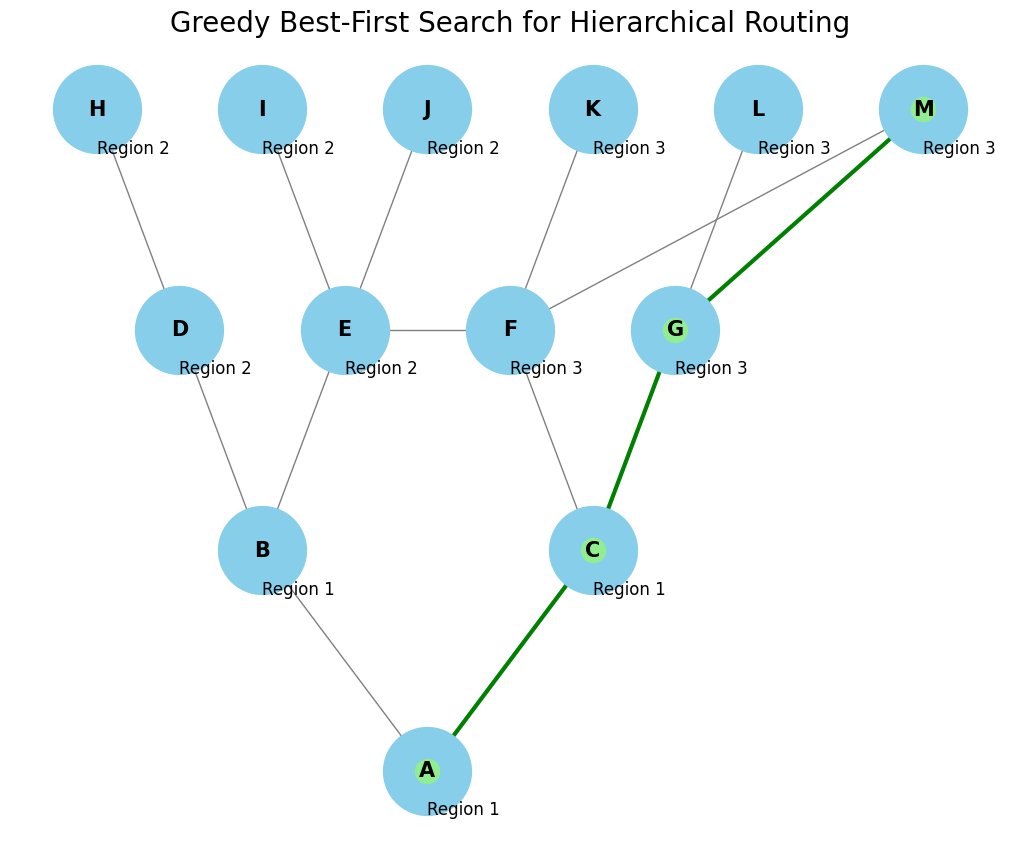

In [ ]:
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': ['H'],
    'E': ['I', 'J'],
    'F': ['K' , 'M' , 'E'],
    'G': ['L', 'M'],
    'H': [],
    'I': [],
    'J': [],
    'K': [],
    'L': [],
    'M': []
}

heuristic = {
    'A': 8,
    'B': 6,
    'C': 7,
    'D': 5,
    'E': 4,
    'F': 5,
    'G': 4,
    'H': 3,
    'I': 2,
    'J': 1,
    'K': 3,
    'L': 2,
    'M': 1
}

region_map = {
    'A': 1, 'B': 1, 'C': 1,
    'D': 2, 'E': 2,
    'F': 3, 'G': 3,
    'H': 2, 'I': 2, 'J': 2,
    'K': 3, 'L': 3, 'M': 3
}


pos = {
    'A': (0, 0),
    'B': (-1, 1),
    'C': (1, 1),
    'D': (-1.5, 2),
    'E': (-0.5, 2),
    'F': (0.5, 2),
    'G': (1.5, 2),
    'H': (-2, 3),
    'I': (-1, 3),
    'J': (0, 3),
    'K': (1, 3),
    'L': (2, 3),
    'M': (3, 3)
}

start_node = 'A'
goal_node = 'M'
result_path = greedy_best_first_search_hierarchical(graph, start_node, goal_node, heuristic, region_map)

print("Path from {} to {}: {}".format(start_node, goal_node, result_path))

visualize_graph(graph, result_path, pos, region_map)

***

<div style="color:white;
           display:fill;
           border-radius:5px;
           background-color:#5642C5;
           font-size:110%;
           font-family:Verdana;
           letter-spacing:0.5px">
        <p style="padding: 10px;
              color:white;">
            Hope you liked today's class!Z
        </p>
    </div>

<center><img src='https://media4.giphy.com/media/M9gbBd9nbDrOTu1Mqx/giphy.gif?cid=790b7611704aa2ca4e403287801480a6c753abf45f3e6242&rid=giphy.gif&ct=s'
     height=120px width=160px /></center>




***